In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow import keras
import seaborn as sns
import os
from datetime import datetime

import warnings
warnings.filterwarnings("ignore")

In [3]:
data = pd.read_csv('all_stocks_5yr.csv', delimiter=',', on_bad_lines='skip')
print(data.shape)
print(data.sample(7))

(619040, 7)
              date    open      high       low   close   volume  Name
466064  2016-05-17   76.02   76.8600   75.5900   75.91  1582800   PRU
48382   2016-01-12  102.16  105.1800  101.6500  104.65  1943386  ANDV
478722  2015-12-09  553.76  562.8604  543.0000  547.39   566715  REGN
24321   2014-09-11   55.08   55.6300   55.0300   55.43  4344106   AIG
542826  2016-12-29   35.09   35.3800   34.7929   35.01  2179696   TPR
148524  2017-02-17  118.97  119.3800  118.0900  118.61  1435535  CTAS
472258  2015-12-21  121.28  121.2800  114.4000  115.71  5069818   PXD


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 619040 entries, 0 to 619039
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   date    619040 non-null  object 
 1   open    619029 non-null  float64
 2   high    619032 non-null  float64
 3   low     619032 non-null  float64
 4   close   619040 non-null  float64
 5   volume  619040 non-null  int64  
 6   Name    619040 non-null  object 
dtypes: float64(4), int64(1), object(2)
memory usage: 33.1+ MB


In [6]:
data['date'] = pd.to_datetime(data['date'])
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 619040 entries, 0 to 619039
Data columns (total 7 columns):
 #   Column  Non-Null Count   Dtype         
---  ------  --------------   -----         
 0   date    619040 non-null  datetime64[ns]
 1   open    619029 non-null  float64       
 2   high    619032 non-null  float64       
 3   low     619032 non-null  float64       
 4   close   619040 non-null  float64       
 5   volume  619040 non-null  int64         
 6   Name    619040 non-null  object        
dtypes: datetime64[ns](1), float64(4), int64(1), object(1)
memory usage: 33.1+ MB


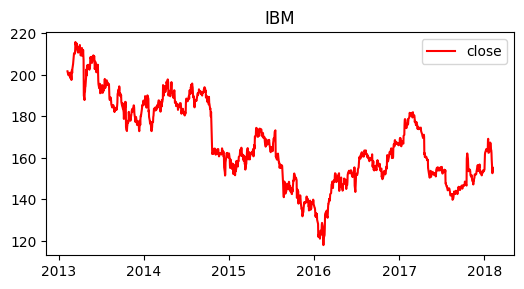

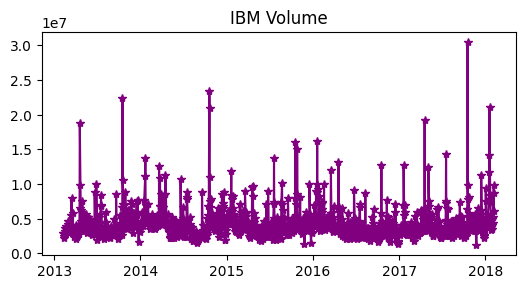

In [ ]:
#companies = ['AAPL', 'AMD', 'FB', 'GOOGL', 'AMZN', 'NVDA', 'EBAY', 'CSCO', 'IBM']
companies = ['IBM']
plt.figure(figsize=(15, 8))
for index, company in enumerate(companies, 1):
    plt.subplot(3, 3, index)
    c = data[data['Name'] == company]
    plt.plot(c['date'], c['close'], c="r", label="close", marker="")
    #plt.plot(c['date'], c['open'], c="g", label="open", marker="^")
    plt.title(company)
    plt.legend()
    plt.tight_layout()


#Volume is the number of IBM (or any company) shares traded during a given period (usually one day)
plt.figure(figsize=(15, 8))
for index, company in enumerate(companies, 1):
    plt.subplot(3, 3, index)
    c = data[data['Name'] == company]
    plt.plot(c['date'], c['volume'], c='purple', marker='*')
    plt.title(f"{company} Volume")
    plt.tight_layout()

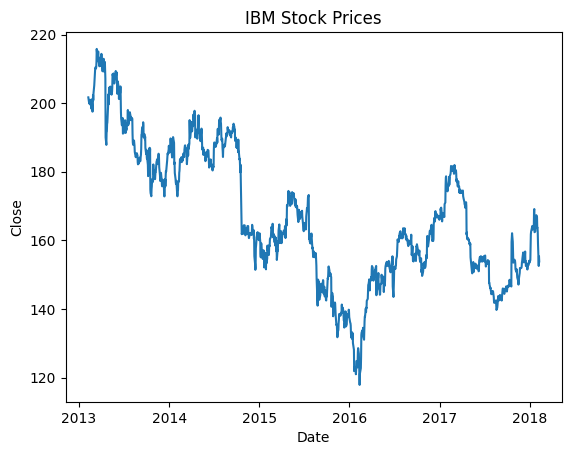

In [24]:
IBM = data[data['Name'] == 'IBM']
prediction_range = IBM.loc[(IBM ['date'] > datetime(2013,1,1))
 & (IBM ['date']<datetime(2018,1,1))]
plt.plot(IBM ['date'],IBM ['close'])
plt.xlabel("Date")
plt.ylabel("Close")
plt.title("IBM Stock Prices")
plt.show()

In [25]:
close_data = IBM.filter(['close'])
dataset = close_data.values
training = int(np.ceil(len(dataset) * .95))
print(training)

1197


In [27]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler(feature_range=(0, 1))
scaled_data = scaler.fit_transform(dataset)

train_data = scaled_data[0:int(training), :]
# prepare feature and labels
x_train = []
y_train = []

for i in range(60, len(train_data)):
    x_train.append(train_data[i-60:i, 0])
    y_train.append(train_data[i, 0])

x_train, y_train = np.array(x_train), np.array(y_train)
x_train = np.reshape(x_train, (x_train.shape[0], x_train.shape[1], 1))

In [35]:
model = keras.models.Sequential()
model.add(keras.layers.Input(shape=(x_train.shape[1], 1)))
model.add(keras.layers.LSTM(units=128, return_sequences=True))
model.add(keras.layers.Dropout(0.2))
model.add(keras.layers.LSTM(units=64))
model.add(keras.layers.Dropout(0.2))
model.add(keras.layers.Dense(32, activation="relu"))
model.add(keras.layers.Dense(1))
model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_10 (LSTM)                  │ (None, 60, 128)        │        66,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 60, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_11 (LSTM)                  │ (None, 64)             │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 118,081 (461.25 KB)

 Trainable params: 118,081 (461.25 KB)

 Non-trainable params: 0 (0.00 B)

In [36]:
model.compile(optimizer='adam',
              loss='mean_squared_error')
history = model.fit(x_train,
                    y_train,
                    epochs=10)

Epoch 1/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 7s 134ms/step - loss: 0.0245
Epoch 2/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 84ms/step - loss: 0.0044
Epoch 3/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 68ms/step - loss: 0.0039
Epoch 4/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 86ms/step - loss: 0.0031
Epoch 5/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 93ms/step - loss: 0.0029
Epoch 6/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 88ms/step - loss: 0.0027
Epoch 7/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 65ms/step - loss: 0.0029
Epoch 8/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 93ms/step - loss: 0.0028
Epoch 9/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 3s 85ms/step - loss: 0.0024
Epoch 10/10
36/36 ━━━━━━━━━━━━━━━━━━━━ 2s 60ms/step - loss: 0.0024


In [37]:
test_data = scaled_data[training - 60:, :]
x_test = []
y_test = dataset[training:, :]
for i in range(60, len(test_data)):
    x_test.append(test_data[i-60:i, 0])

x_test = np.array(x_test)
x_test = np.reshape(x_test, (x_test.shape[0], x_test.shape[1], 1))

predictions = model.predict(x_test)
predictions = scaler.inverse_transform(predictions)

mse = np.mean(((predictions - y_test) ** 2))
rmse = np.sqrt(mse)

print("MSE", mse)
print("RMSE", np.sqrt(mse))

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 310ms/step
MSE 15.792248706669566
RMSE 3.973946238522807


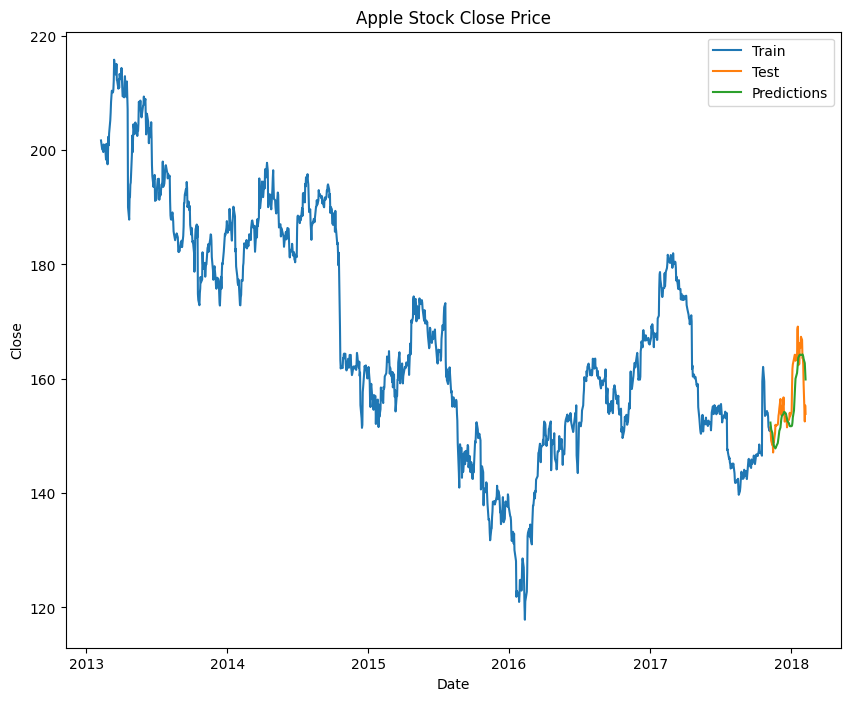

In [38]:
train = IBM[:training]
test = IBM[training:]
test['Predictions'] = predictions

plt.figure(figsize=(10, 8))
plt.plot(train['date'], train['close'])
plt.plot(test['date'], test[['close', 'Predictions']])
plt.title('Apple Stock Close Price')
plt.xlabel('Date')
plt.ylabel("Close")
plt.legend(['Train', 'Test', 'Predictions'])